# BÁO CÁO HỌC PHẦN MÁY HỌC (MACHINE LEARNING)
## ĐỀ TÀI: PHÂN LOẠI TIN NHẮN RÁC (SPAM MESSAGE CLASSIFICATION)
**Học phần:** Máy học (Machine Learning)  
**Giảng viên hướng dẫn (MCL):** ThS. Lê Thị Thùy Trang (FIT - DNU)  
**Thuật toán chính:** Naive Bayes (MultinomialNB, BernoulliNB)  
**Thuật toán so sánh:** K-Nearest Neighbors (K-NN), Cây quyết định (Decision Tree - Gini/Entropy)  
**Tập dữ liệu:** SMS Spam Collection (UCI Machine Learning Repository)  

---
### MỤC LỤC NOTEBOOK:
1. **Phần 1:** Nạp các thư viện và cấu hình môi trường
2. **Phần 2:** Nạp dữ liệu và Phân tích khám phá (EDA - Bài 2 MCL)
3. **Phần 3:** Tiền xử lý dữ liệu văn bản và Trích xuất đặc trưng (Bài 2 & 4 MCL)
4. **Phần 4:** Huấn luyện thuật toán Naive Bayes (Bài 4 MCL)
5. **Phần 5:** Huấn luyện các thuật toán so sánh: K-NN (Bài 3) và Decision Tree (Bài 5)
6. **Phần 6:** Đánh giá hiệu năng và So sánh đa chiều (Confusion Matrix, Accuracy, Precision, Recall, F1)
7. **Phần 7:** Giải thích mô hình: Phân tích Top từ khóa đặc trưng (Feature Importance)
8. **Phần 8:** Xây dựng hàm Dự đoán tin nhắn mới và Kiểm thử thực tế
9. **Phần 9:** Phân tích lỗi (Error Analysis: False Positive vs False Negative)


---
## PHẦN 1: NẠP CÁC THƯ VIỆN VÀ CẤU HÌNH MÔI TRƯỜNG
Sử dụng các thư viện khoa học dữ liệu chuẩn mực của Python:
- `pandas`, `numpy`: Quản lý dữ liệu dạng bảng và tính toán ma trận số học.
- `matplotlib`, `seaborn`: Trực quan hóa dữ liệu và biểu đồ hiệu năng.
- `scikit-learn`: Xây dựng pipeline tiền xử lý, huấn luyện và đánh giá mô hình học máy.


In [1]:
import re
import string
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Các module từ Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, 
    recall_score, f1_score, classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 120

print("Đã nạp toàn bộ thư viện thành công!")


Đã nạp toàn bộ thư viện thành công!


---
## PHẦN 2: NẠP DỮ LIỆU VÀ PHÂN TÍCH KHÁM PHÁ (EDA - BÀI 2 MCL)
Bộ dữ liệu `SMS Spam Collection` gồm các tin nhắn được gán nhãn:
- `ham`: Tin nhắn bình thường hợp lệ.
- `spam`: Tin nhắn rác (quảng cáo, lừa đảo, mã độc).

Theo **Bài 2 MCL**, bước đầu tiên là kiểm tra cấu trúc, loại bỏ bản ghi trùng lặp và phân tích độ mất cân bằng giữa các lớp (Class Imbalance).


In [2]:
# 1. Đọc dữ liệu
df_raw = pd.read_csv('data/SMSSpamCollection', sep='\t', names=['label', 'message'], encoding='utf-8')
print(f"Tổng số mẫu ban đầu: {len(df_raw)} tin nhắn")
df_raw.head()


Tổng số mẫu ban đầu: 5572 tin nhắn


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# 2. Làm sạch bản ghi trùng lặp và missing values (Bài 2 MCL)
df = df_raw.copy()
df.drop_duplicates(subset=['message'], keep='first', inplace=True)
df.dropna(subset=['message', 'label'], inplace=True)
df.reset_index(drop=True, inplace=True)

# Mã hóa nhãn nhị phân: ham -> 0, spam -> 1
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# Thêm đặc trưng độ dài tin nhắn (số ký tự và số từ)
df['char_count'] = df['message'].apply(len)
df['word_count'] = df['message'].apply(lambda x: len(x.split()))

print(f"Số lượng mẫu sau khi loại bỏ trùng lặp: {len(df)} tin nhắn")
print(f"Số lượng tin HAM:  {sum(df['label_num'] == 0)} ({sum(df['label_num'] == 0)/len(df)*100:.2f}%)")
print(f"Số lượng tin SPAM: {sum(df['label_num'] == 1)} ({sum(df['label_num'] == 1)/len(df)*100:.2f}%)")


Số lượng mẫu sau khi loại bỏ trùng lặp: 5169 tin nhắn
Số lượng tin HAM:  4516 (87.37%)
Số lượng tin SPAM: 653 (12.63%)


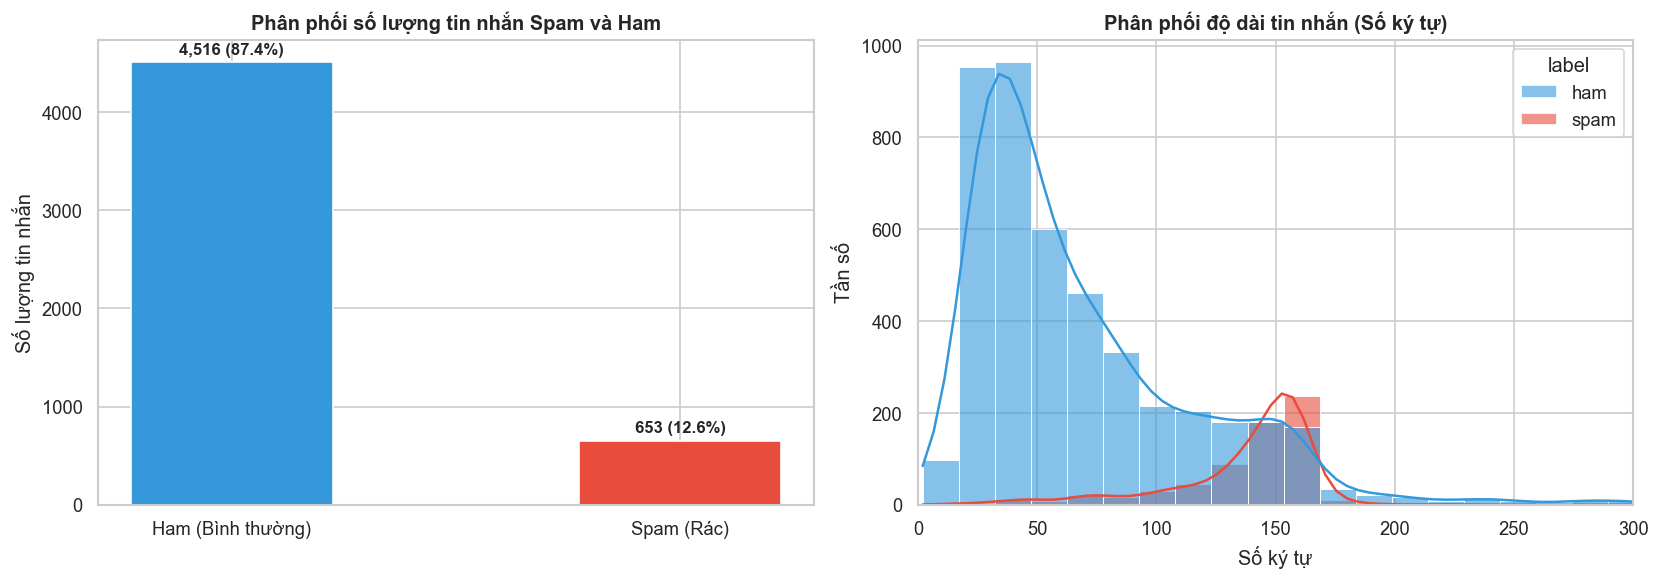

In [4]:
# 3. Trực quan hóa phân phối nhãn và độ dài tin nhắn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Tỷ lệ phân phối nhãn
counts = df['label'].value_counts()
colors = ['#3498db', '#e74c3c']
bars = ax1.bar(['Ham (Bình thường)', 'Spam (Rác)'], counts.values, color=colors, width=0.45)
ax1.set_title('Phân phối số lượng tin nhắn Spam và Ham', fontsize=12, fontweight='bold')
ax1.set_ylabel('Số lượng tin nhắn')
for bar in bars:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 50, f'{h:,} ({pct:.1f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Biểu đồ 2: Phân phối độ dài ký tự
sns.histplot(data=df, x='char_count', hue='label', bins=60, kde=True,
             palette={'ham': '#3498db', 'spam': '#e74c3c'}, ax=ax2, alpha=0.6)
ax2.set_xlim(0, 300)
ax2.set_title('Phân phối độ dài tin nhắn (Số ký tự)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Số ký tự')
ax2.set_ylabel('Tần số')

plt.tight_layout()
plt.show()


---
## PHẦN 3: TIỀN XỬ LÝ DỮ LIỆU VĂN BẢN VÀ TRÍCH XUẤT ĐẶC TRƯNG
Quy trình tiền xử lý văn bản gồm các bước:
1. Chuyển chữ thường (Lowercasing)
2. Loại bỏ liên kết URL, email, chuỗi số điện thoại
3. Loại bỏ dấu câu và ký tự đặc biệt
4. Lọc từ dừng tiếng Anh (Stopwords)
5. Vector hóa văn bản bằng mô hình Túi từ **Bag-of-Words (`CountVectorizer`)**
6. Phân chia Train/Test ($80:20$) có bảo toàn tỷ lệ nhãn (`stratify=y`)


In [5]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Áp dụng làm sạch
df['cleaned_message'] = df['message'].apply(clean_text)
print("Ví dụ văn bản trước và sau khi làm sạch:")
print("-" * 60)
print("GỐC:       ", df['message'].iloc[2])
print("LÀM SẠCH:  ", df['cleaned_message'].iloc[2])


Ví dụ văn bản trước và sau khi làm sạch:
------------------------------------------------------------
GỐC:        Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
LÀM SẠCH:   free entry in a wkly comp to win fa cup final tkts st may text fa to to receive entry questionstd txt ratetcs apply over s


In [6]:
# Phân chia tập dữ liệu 80% Train và 20% Test (Bảo toàn tỷ lệ phân tầng)
X = df['cleaned_message']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Vector hóa văn bản với CountVectorizer
vectorizer = CountVectorizer(stop_words='english', min_df=2)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Kích thước tập Train: {X_train_vec.shape[0]} mẫu")
print(f"Kích thước tập Test:  {X_test_vec.shape[0]} mẫu")
print(f"Kích thước không gian từ điển (|V|): {X_train_vec.shape[1]} từ đặc trưng")


Kích thước tập Train: 4135 mẫu
Kích thước tập Test:  1034 mẫu
Kích thước không gian từ điển (|V|): 2806 từ đặc trưng


---
## PHẦN 4 & 5: HUẤN LUYỆN CÁC THUẬT TOÁN HỌC MÁY
Huấn luyện 5 mô hình theo đúng kiến thức học phần:
1. **Multinomial Naive Bayes (`alpha=1.0`)** (Bài 4 MCL - tần suất từ)
2. **Bernoulli Naive Bayes (`alpha=1.0`)** (Bài 4 MCL - nhị phân 0/1)
3. **K-Nearest Neighbors ($K=5$, Euclidean)** (Bài 3 MCL)
4. **Decision Tree (CART - Gini Impurity)** (Bài 5 MCL)
5. **Decision Tree (ID3 - Entropy / Information Gain)** (Bài 5 MCL)


In [7]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Bernoulli Naive Bayes': BernoulliNB(alpha=1.0),
    'K-Nearest Neighbors (K=5)': KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    'Decision Tree (Gini)': DecisionTreeClassifier(criterion='gini', random_state=42),
    'Decision Tree (Entropy)': DecisionTreeClassifier(criterion='entropy', random_state=42)
}

results = []
confusion_matrices = {}
trained_models = {}

for name, model in models.items():
    # Đo thời gian huấn luyện
    t0 = time.time()
    model.fit(X_train_vec, y_train)
    train_time = (time.time() - t0) * 1000
    
    # Đo thời gian dự đoán
    t1 = time.time()
    y_pred = model.predict(X_test_vec)
    pred_time = (time.time() - t1) * 1000
    
    # Tính các chỉ số
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'Train Time (ms)': train_time,
        'Pred Time (ms)': pred_time
    })
    confusion_matrices[name] = cm
    trained_models[name] = model

df_results = pd.DataFrame(results)
df_results


,Model,Accuracy,Precision,Recall,F1-Score,TP,TN,FP,FN,Train Time (ms),Pred Time (ms)
0,Multinomial Naive Bayes,0.979691,0.929688,0.908397,0.918919,119,894,9,12,11.045933,5.837202
1,Bernoulli Naive Bayes,0.981625,0.982759,0.870229,0.923077,114,901,2,17,2.242088,0.699759
2,K-Nearest Neighbors (K=5),0.914894,0.977778,0.335878,0.500000,44,902,1,87,0.827312,220.190048
3,Decision Tree (Gini),0.962282,0.859375,0.839695,0.849421,110,885,18,21,144.937277,0.638247
4,Decision Tree (Entropy),0.959381,0.850394,0.824427,0.837209,108,884,19,23,94.598293,0.856161


---
## PHẦN 6: ĐÁNH GIÁ HIỆU NĂNG VÀ SO SÁNH ĐA CHIỀU (BÀI 3 MCL)
Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix) và so sánh các chỉ số Accuracy, Precision, Recall, F1 giữa các mô hình.


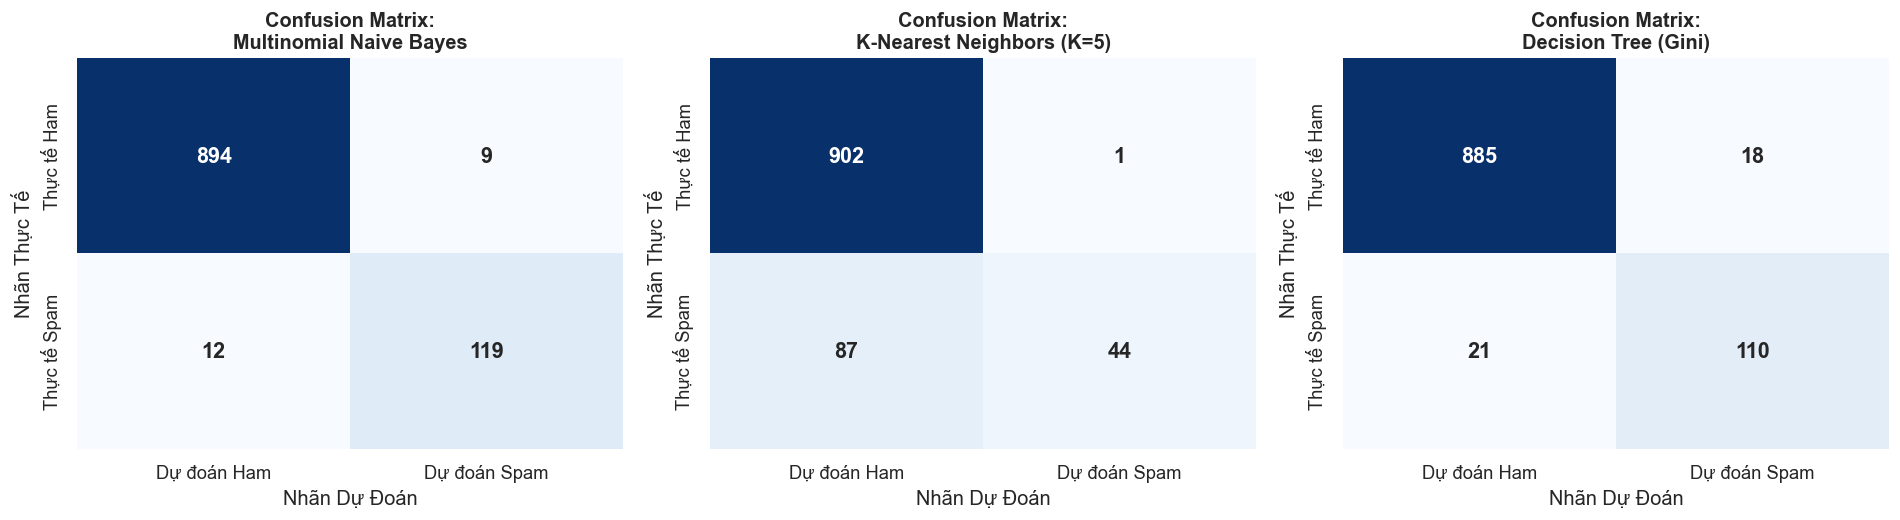

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

selected = [
    ('Multinomial Naive Bayes', 0),
    ('K-Nearest Neighbors (K=5)', 1),
    ('Decision Tree (Gini)', 2)
]

for name, idx in selected:
    ax = axes[idx]
    cm = confusion_matrices[name]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Dự đoán Ham', 'Dự đoán Spam'],
                yticklabels=['Thực tế Ham', 'Thực tế Spam'],
                annot_kws={'size': 13, 'weight': 'bold'})
    ax.set_title(f'Confusion Matrix:\n{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Nhãn Dự Đoán')
    ax.set_ylabel('Nhãn Thực Tế')

plt.tight_layout()
plt.show()


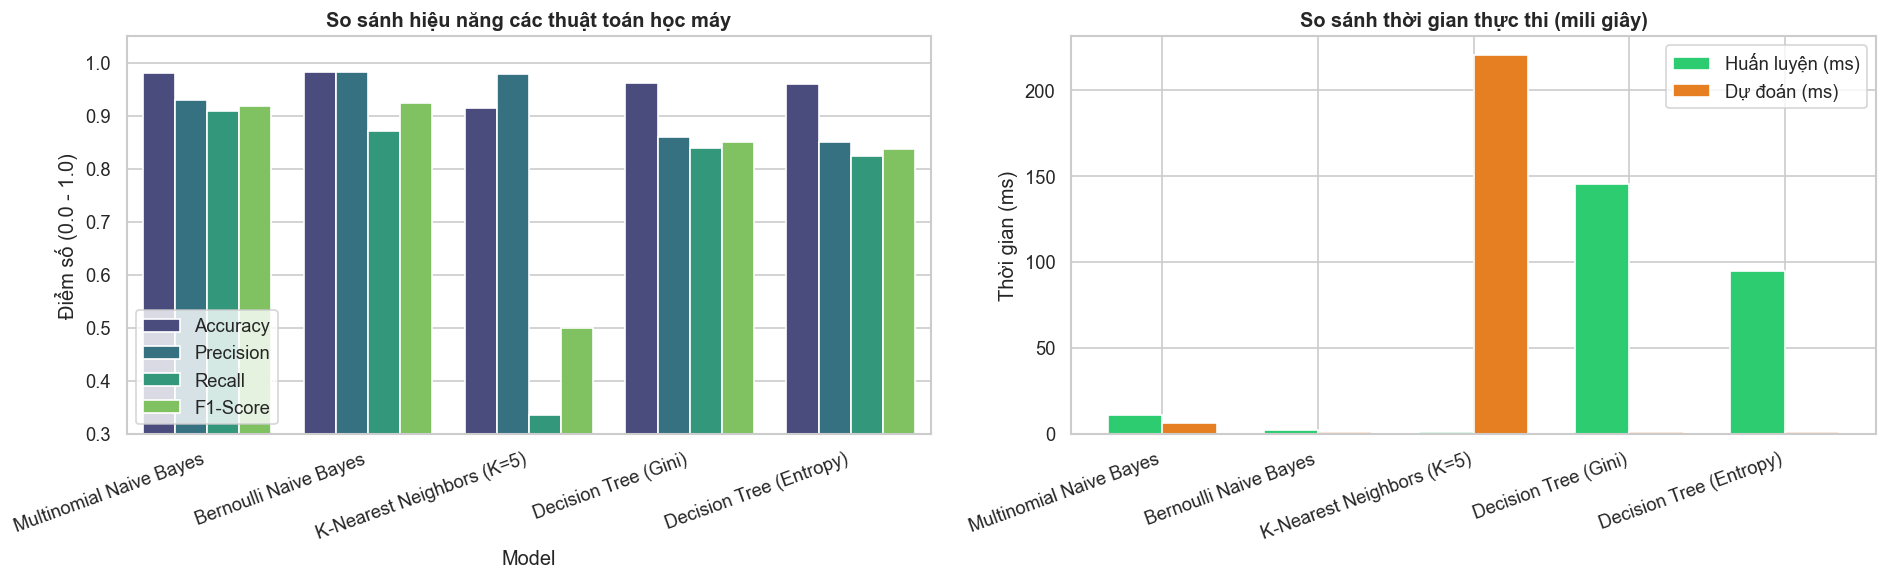

In [9]:
# Vẽ biểu đồ so sánh các chỉ số chất lượng
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
df_melted = pd.melt(df_results, id_vars=['Model'], value_vars=metrics,
                    var_name='Metric', value_name='Score')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị 1: So sánh chất lượng phân loại
sns.barplot(data=df_melted, x='Model', y='Score', hue='Metric', palette='viridis', ax=ax1)
ax1.set_title('So sánh hiệu năng các thuật toán học máy', fontsize=12, fontweight='bold')
ax1.set_ylim(0.3, 1.05)
ax1.set_ylabel('Điểm số (0.0 - 1.0)')
ax1.set_xticklabels(df_results['Model'], rotation=20, ha='right')
ax1.legend(loc='lower left')

# Đồ thị 2: So sánh thời gian thực thi
x = np.arange(len(df_results['Model']))
w = 0.35
ax2.bar(x - w/2, df_results['Train Time (ms)'], w, label='Huấn luyện (ms)', color='#2ecc71')
ax2.bar(x + w/2, df_results['Pred Time (ms)'], w, label='Dự đoán (ms)', color='#e67e22')
ax2.set_title('So sánh thời gian thực thi (mili giây)', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(df_results['Model'], rotation=20, ha='right')
ax2.set_ylabel('Thời gian (ms)')
ax2.legend()

plt.tight_layout()
plt.show()


---
## PHẦN 7: GIẢI THÍCH MÔ HÌNH: TOP TỪ KHÓA ĐẶC TRƯNG (EXPLAINABLE AI)
Trích xuất xác suất có điều kiện $P(\text{từ} | \text{lớp})$ từ mô hình Naive Bayes để quan sát các từ khóa mang tính quyết định nhất.


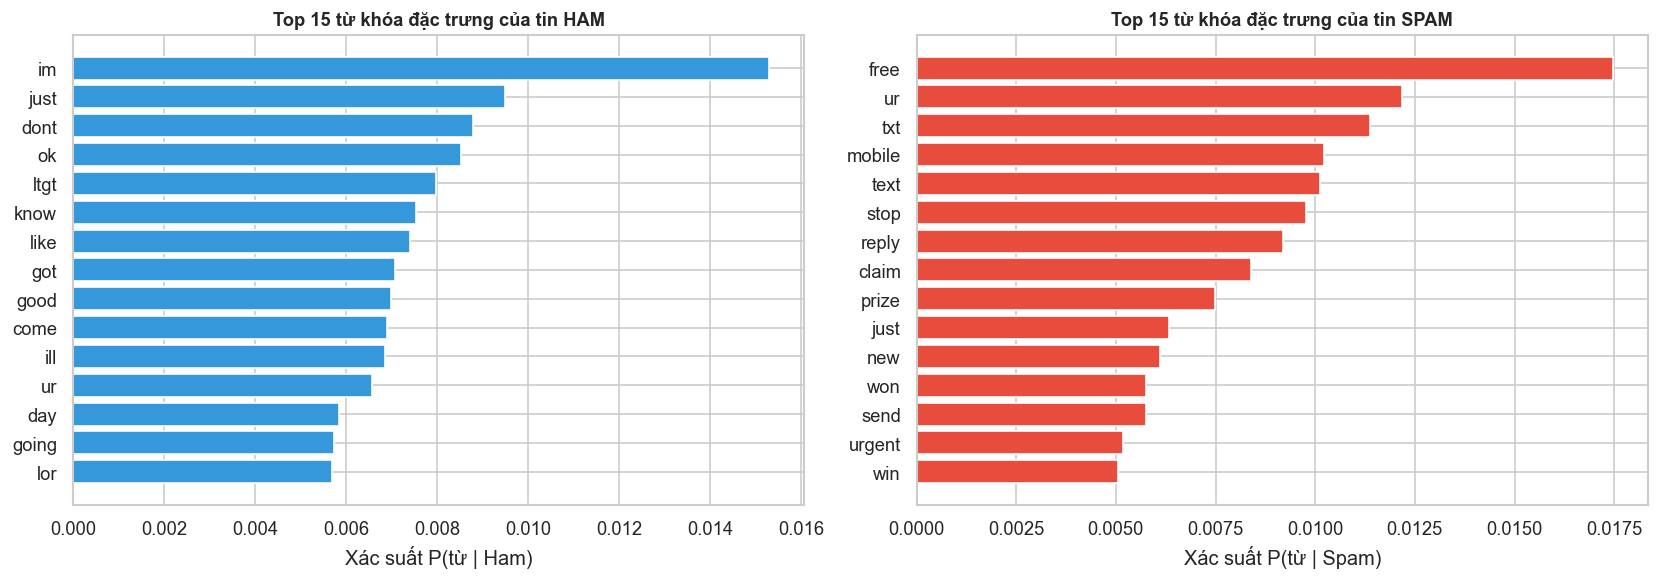

In [10]:
nb_model = trained_models['Multinomial Naive Bayes']
feature_names = np.array(vectorizer.get_feature_names_out())
ham_log_prob = nb_model.feature_log_prob_[0]
spam_log_prob = nb_model.feature_log_prob_[1]

top_n = 15
top_spam_idx = np.argsort(spam_log_prob)[-top_n:]
top_ham_idx = np.argsort(ham_log_prob)[-top_n:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.barh(feature_names[top_ham_idx], np.exp(ham_log_prob[top_ham_idx]), color='#3498db')
ax1.set_title(f'Top {top_n} từ khóa đặc trưng của tin HAM', fontsize=11, fontweight='bold')
ax1.set_xlabel('Xác suất P(từ | Ham)')

ax2.barh(feature_names[top_spam_idx], np.exp(spam_log_prob[top_spam_idx]), color='#e74c3c')
ax2.set_title(f'Top {top_n} từ khóa đặc trưng của tin SPAM', fontsize=11, fontweight='bold')
ax2.set_xlabel('Xác suất P(từ | Spam)')

plt.tight_layout()
plt.show()


---
## PHẦN 8: XÂY DỰNG HÀM DỰ ĐOÁN TIN NHẮN MỚI VÀ KIỂM THỬ THỰC TẾ
Xây dựng hàm `predict_sms()` nhận chuỗi tin nhắn bất kỳ, trích xuất đặc trưng và đưa ra kết luận kèm xác suất tin cậy.


In [11]:
def predict_sms(message, model=nb_model, vectorizer=vectorizer):
    cleaned = clean_text(message)
    vec = vectorizer.transform([cleaned])
    pred = model.predict(vec)[0]
    proba = model.predict_proba(vec)[0]
    
    label = "SPAM" if pred == 1 else "HAM"
    return {
        'message': message,
        'label': label,
        'prob_ham': proba[0],
        'prob_spam': proba[1]
    }

# Kiểm thử các tình huống tin nhắn đa dạng
test_cases = [
    "Congratulations! You have won a $1,000 Walmart gift card. Click here to claim your prize now: http://spam.com",
    "Urgent! Please call 09061104276 from landline. Your complimentary 4* Tenerife Holiday or £5000 cash await!",
    "Hey bro, are we still meeting for lunch at 12pm today? Let me know.",
    "Can you send me the lecture slides for Machine Learning course? Thanks!",
    "WINNER!! As a valued network customer you have been selected to receive a £900 prize reward! To claim call 09061701461",
    "Hi mom, I will be home a bit late tonight because I have to finish my group project."
]

print("=" * 80)
print("KẾT QUẢ DỰ ĐOÁN TIN NHẮN THỰC TẾ:")
print("=" * 80)
for idx, text in enumerate(test_cases, 1):
    res = predict_sms(text)
    print(f"\n[{idx}] Nội dung: \"{res['message']}\"")
    print(f" -> KẾT LUẬN: [{res['label']}] (P(Spam) = {res['prob_spam']*100:.2f}%, P(Ham) = {res['prob_ham']*100:.2f}%)")


KẾT QUẢ DỰ ĐOÁN TIN NHẮN THỰC TẾ:

[1] Nội dung: "Congratulations! You have won a $1,000 Walmart gift card. Click here to claim your prize now: http://spam.com"
 -> KẾT LUẬN: [SPAM] (P(Spam) = 100.00%, P(Ham) = 0.00%)

[2] Nội dung: "Urgent! Please call 09061104276 from landline. Your complimentary 4* Tenerife Holiday or £5000 cash await!"
 -> KẾT LUẬN: [SPAM] (P(Spam) = 100.00%, P(Ham) = 0.00%)

[3] Nội dung: "Hey bro, are we still meeting for lunch at 12pm today? Let me know."
 -> KẾT LUẬN: [HAM] (P(Spam) = 0.00%, P(Ham) = 100.00%)

[4] Nội dung: "Can you send me the lecture slides for Machine Learning course? Thanks!"
 -> KẾT LUẬN: [HAM] (P(Spam) = 2.04%, P(Ham) = 97.96%)

[5] Nội dung: "WINNER!! As a valued network customer you have been selected to receive a £900 prize reward! To claim call 09061701461"
 -> KẾT LUẬN: [SPAM] (P(Spam) = 100.00%, P(Ham) = 0.00%)

[6] Nội dung: "Hi mom, I will be home a bit late tonight because I have to finish my group project."
 -> KẾT LUẬN: [HAM] (

---
## PHẦN 9: PHÂN TÍCH LỖI (ERROR ANALYSIS: FALSE POSITIVE & FALSE NEGATIVE)
Xem xét cụ thể các trường hợp mô hình Naive Bayes phân loại sai trên tập kiểm thử để hiểu rõ nguyên nhân.


In [12]:
y_pred_nb = nb_model.predict(X_test_vec)
test_df = pd.DataFrame({
    'text': X_test.values,
    'actual': y_test.values,
    'predicted': y_pred_nb
})

# False Positives: Thực tế Ham nhưng bị đoán Spam
fps = test_df[(test_df['actual'] == 0) & (test_df['predicted'] == 1)]
print(f"Tổng số mẫu False Positive (Ham nhầm thành Spam): {len(fps)}")
print("Ví dụ 3 mẫu FP tiêu biểu:")
for idx, row in fps.head(3).iterrows():
    print(f"- {row['text']}")

print("\n" + "=" * 60 + "\n")

# False Negatives: Thực tế Spam nhưng bị đoán Ham
fns = test_df[(test_df['actual'] == 1) & (test_df['predicted'] == 0)]
print(f"Tổng số mẫu False Negative (Spam bị bỏ lọt thành Ham): {len(fns)}")
print("Ví dụ 3 mẫu FN tiêu biểu:")
for idx, row in fns.head(3).iterrows():
    print(f"- {row['text']}")


Tổng số mẫu False Positive (Ham nhầm thành Spam): 9
Ví dụ 3 mẫu FP tiêu biểu:
- i am waiting machan call me once you free
- are you free nowcan i call now
- k k sms chat with me


Tổng số mẫu False Negative (Spam bị bỏ lọt thành Ham): 12
Ví dụ 3 mẫu FN tiêu biểu:
- hi babe its jordan how r u im home from abroad and lonely text me back if u wanna chat xxsp visionsmscom text stop to stopcost p
- asked mobile if chatlines inclu in free mins india cust servs sed yes l er got mega bill dont giv a shit bailiff due in days i o £ want £
- hi its lucy hubby at meetins all day fri i will b alone at hotel u fancy cumin over pls leave msg day lucy x calls£ minmobsmorelkpobox hp fl
